# Three views of Wembanyama’s defensive season

Joseph Smarrelli · September 2026

This notebook recalculates selected findings from the included derived tables. It does not refit the underlying models. See the repository README for the complete source-data build and the accompanying article for interpretation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
p = root / 'projects' / '03_wemby_impact'

## Recalculate the result
The assertions check that the article’s reported quantities agree with the delivered tables.

In [2]:
d = pd.read_csv(p / 'rapm_2025_26.csv')
assert np.allclose(d.o_rapm + d.d_rapm, d.rapm)
rim = pd.read_csv(p / 'rim_control_panel.csv')
assert np.allclose(rim.rim_share_on - rim.rim_share_off, rim.rim_share_delta)
assert np.allclose(rim.rim_fg_on - rim.rim_fg_off, rim.rim_fg_delta)
display(rim.loc[rim.player_id.eq(1641705)])

,player_id,name,rim_share_on,rim_share_off,rim_share_delta,rim_fg_on,rim_fg_off,rim_fg_delta,opp_fg_delta,shots_on
0,1641705,Victor Wembanyama,0.297703,0.376142,-0.078439,0.557342,0.606328,-0.048986,-0.058385,3134


## Inspect the estimates

In [3]:
display(d.sort_values('d_rapm', ascending=False).head(12))

,player_id,o_rapm,d_rapm,rapm,name
0,1641705,2.838630,5.309419,8.148050,Victor Wembanyama
57,203497,-2.393589,5.210282,2.816693,Rudy Gobert
5,1631096,1.222914,4.904254,6.127168,Chet Holmgren
3,1628401,2.244253,4.536475,6.780728,Derrick White
60,1629680,-0.979074,3.712797,2.733723,Matisse Thybulle
108,1641842,-1.803459,3.586729,1.783270,Ronald Holland II
30,1641744,0.030879,3.538620,3.569499,Zach Edey
17,201950,1.156106,3.433600,4.589706,Jrue Holiday
8,1629674,1.949765,3.394891,5.344656,Neemias Queta
14,1627936,1.631981,3.277084,4.909065,Alex Caruso


## Figures

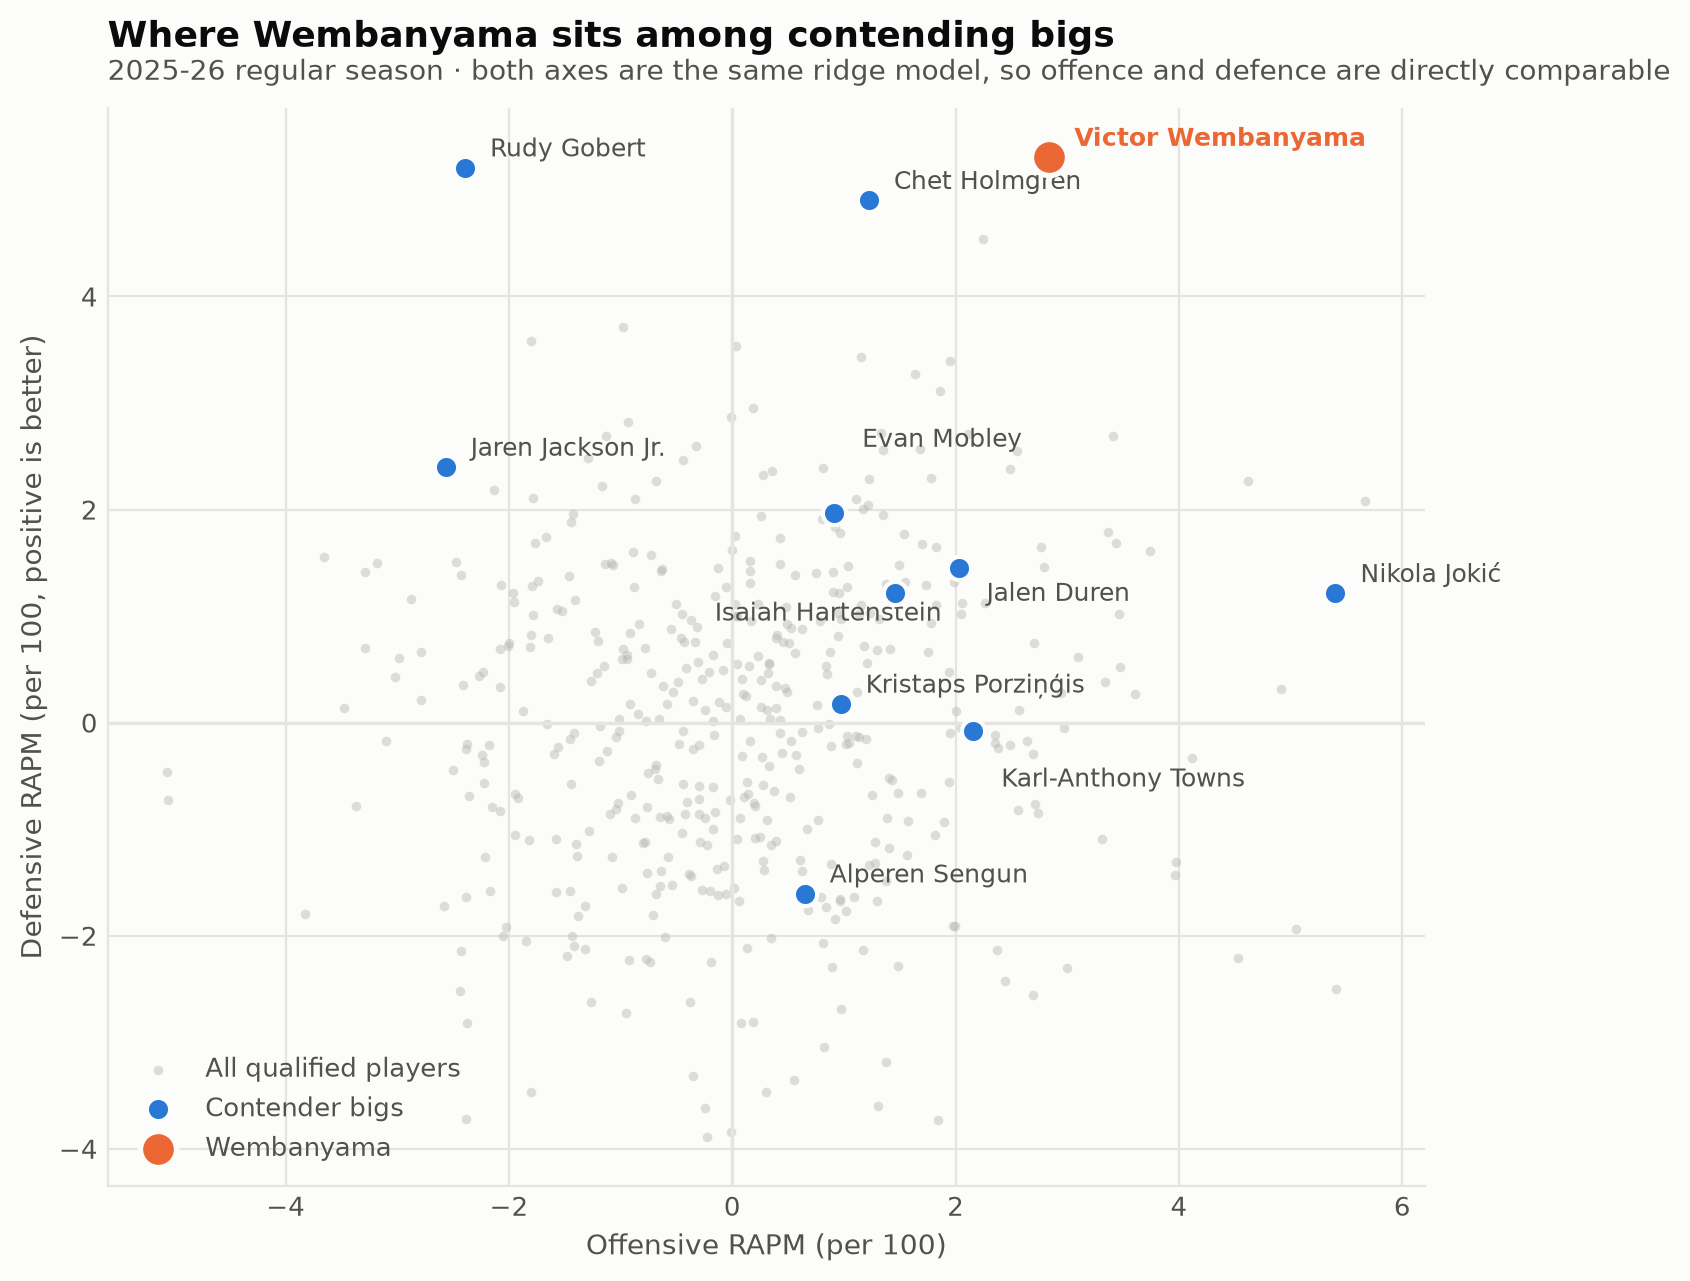

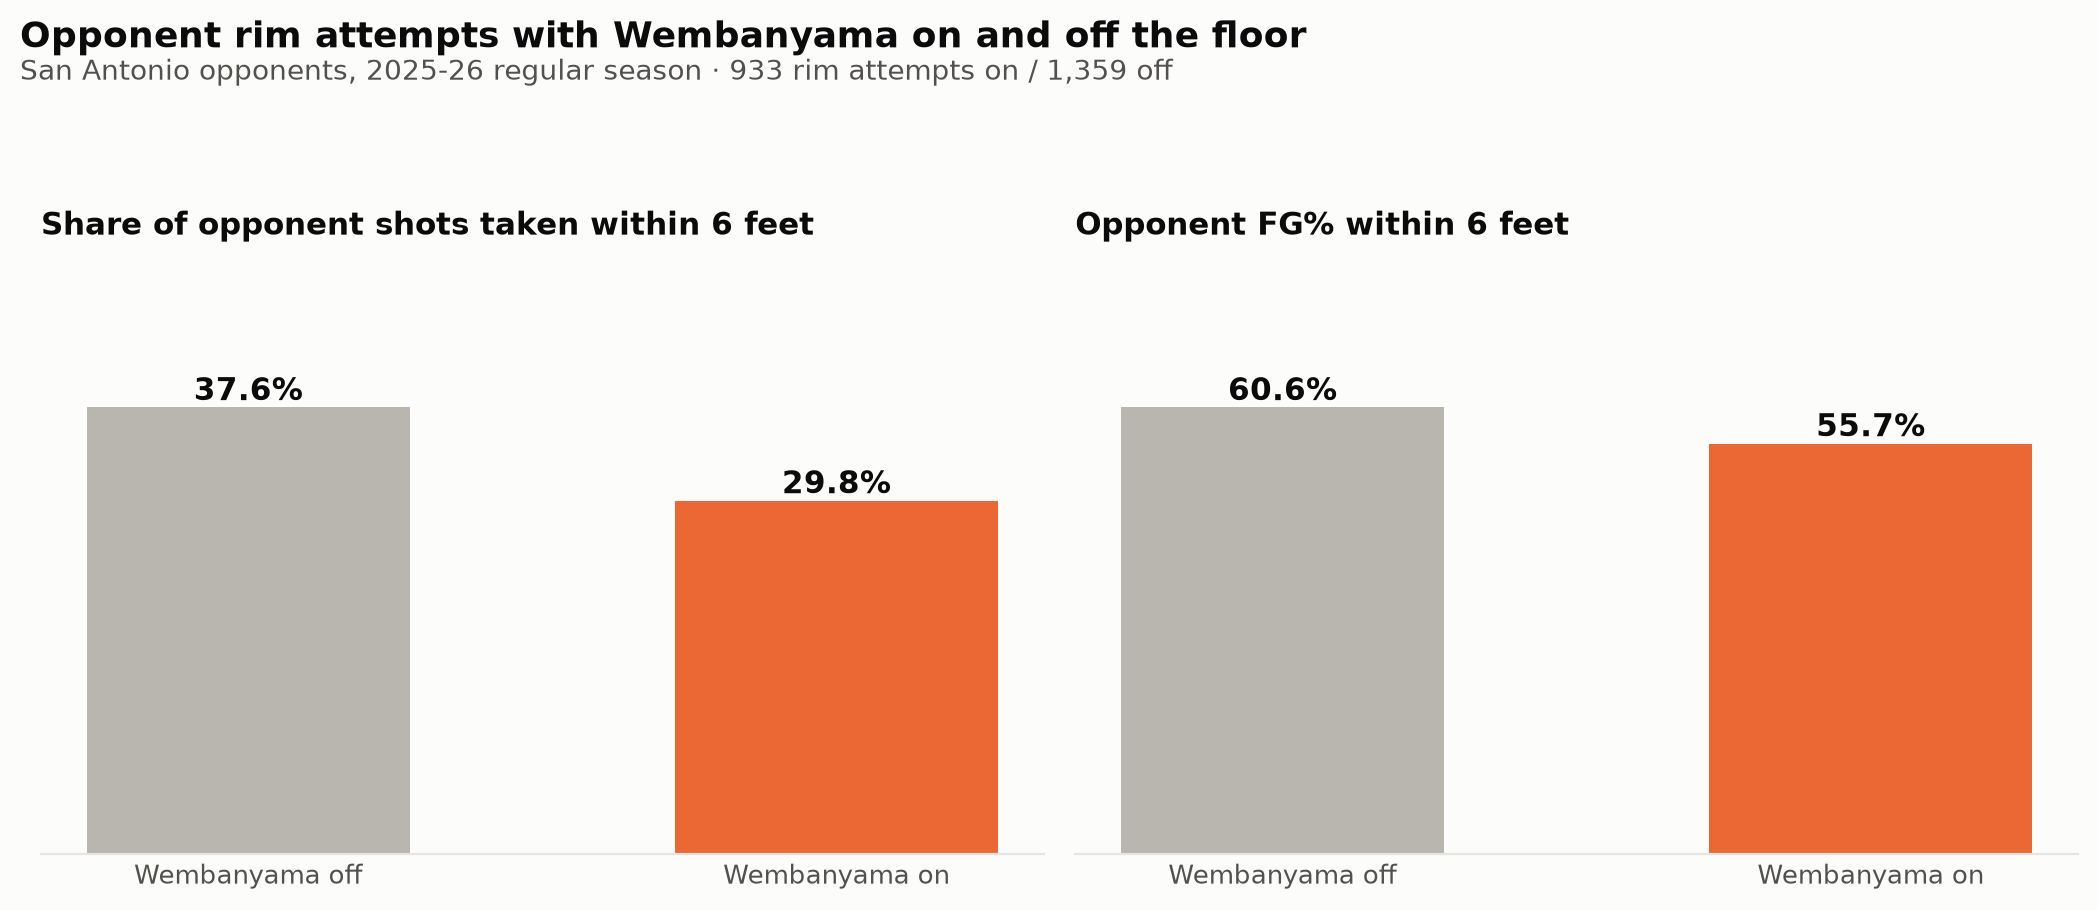

In [4]:
display(Image(filename=str(root / 'projects/03_wemby_impact/figures/rapm_bigs.png')))
display(Image(filename=str(root / 'projects/03_wemby_impact/figures/rim_deterrence.png')))

## Interpretation limits
RAPM adjusts for listed players, not every game condition. Its game-grouped validation score is a tuning diagnostic. Rim comparisons are observational. Matchup totals use the defender field.